In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [2]:
import pandas as pd

df = pd.read_csv("ai-impact-jobs-layoff-risk-dataset.csv")
df.head()

,Age,Education_Level,Years_of_Experience,Industry,Job_Role,Company_Size,Job_Level,Routine_Task_Percentage,Creativity_Requirement,Human_Interaction_Level,AI_Adoption_Level,Number_of_AI_Tools_Used,AI_Usage_Hours_Per_Week,Tasks_Automated_Percentage,AI_Training_Hours,Layoff_Risk
0,59,Master's,6,Finance,Accountant,Medium,Entry,84,21,94,Medium,5,7,40,26,High
1,44,Master's,14,Manufacturing,Production Supervisor,Small,Entry,30,84,68,Low,2,2,14,9,Low
2,36,Bachelor's,7,Retail,Store Manager,Medium,Senior,12,86,71,Low,0,1,6,3,Low
3,27,Bachelor's,6,Finance,Auditor,Large,Entry,90,18,21,Medium,3,10,67,26,High
4,49,High School,12,Finance,Auditor,Small,Entry,49,52,72,Medium,5,13,26,19,Medium


## Random Forest Classifier

A random forest combines many decision trees to predict whether each profile is labeled Low, Medium, or High synthetic layoff risk. We will evaluate it on a held-out test set.

In [9]:
print(df.columns.tolist())

['Age', 'Education_Level', 'Years_of_Experience', 'Industry', 'Job_Role', 'Company_Size', 'Job_Level', 'Routine_Task_Percentage', 'Creativity_Requirement', 'Human_Interaction_Level', 'AI_Adoption_Level', 'Number_of_AI_Tools_Used', 'AI_Usage_Hours_Per_Week', 'Tasks_Automated_Percentage', 'AI_Training_Hours', 'Layoff_Risk']


In [10]:
# Separate the target from the predictors
y = df["Layoff_Risk"]
X = df.drop(columns=["Layoff_Risk"])

# Convert text columns into numbers and fill missing values
X = pd.get_dummies(X)
X = X.fillna(0)

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [11]:
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [53]:
from sklearn.metrics import classification_report, confusion_matrix

train_predictions = rf_model.predict(X_train)
test_predictions = rf_model.predict(X_test)

print("Training results:")
print(classification_report(y_train, train_predictions, zero_division=0))
print("Training confusion matrix:")
print(confusion_matrix(y_train, train_predictions, labels=rf_model.classes_))

print("\nTest results:")
print(classification_report(y_test, test_predictions, zero_division=0))
print("Test confusion matrix:")
print(confusion_matrix(y_test, test_predictions, labels=rf_model.classes_))

Training results:
              precision    recall  f1-score   support

        High       1.00      1.00      1.00      5437
         Low       1.00      1.00      1.00      5282
      Medium       1.00      1.00      1.00      5281

    accuracy                           1.00     16000
   macro avg       1.00      1.00      1.00     16000
weighted avg       1.00      1.00      1.00     16000

Training confusion matrix:
[[5437    0    0]
 [   0 5282    0]
 [   0    0 5281]]

Test results:
              precision    recall  f1-score   support

        High       0.93      0.93      0.93      1360
         Low       0.93      0.92      0.93      1320
      Medium       0.85      0.85      0.85      1320

    accuracy                           0.90      4000
   macro avg       0.90      0.90      0.90      4000
weighted avg       0.90      0.90      0.90      4000

Test confusion matrix:
[[1270    0   90]
 [   0 1217  103]
 [ 100   94 1126]]


In [15]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)
print(classification_report(y_test, baseline_predictions, zero_division=0))

              precision    recall  f1-score   support

        High       0.34      1.00      0.51      1360
         Low       0.00      0.00      0.00      1320
      Medium       0.00      0.00      0.00      1320

    accuracy                           0.34      4000
   macro avg       0.11      0.33      0.17      4000
weighted avg       0.12      0.34      0.17      4000



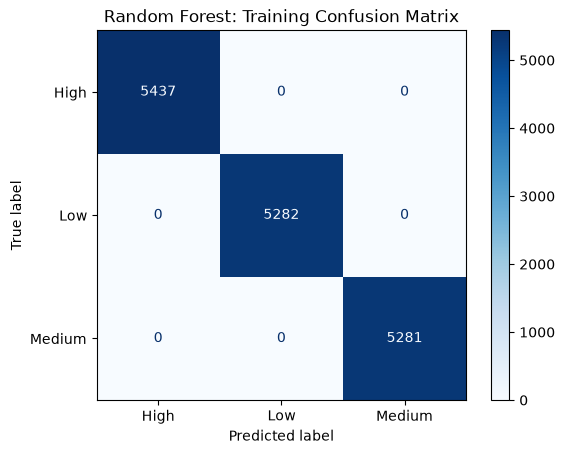

In [46]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_train,
    train_predictions,
    labels=rf_model.classes_,
    display_labels=rf_model.classes_,
    cmap="Blues"
)

plt.title("Random Forest: Training Confusion Matrix")
plt.show()

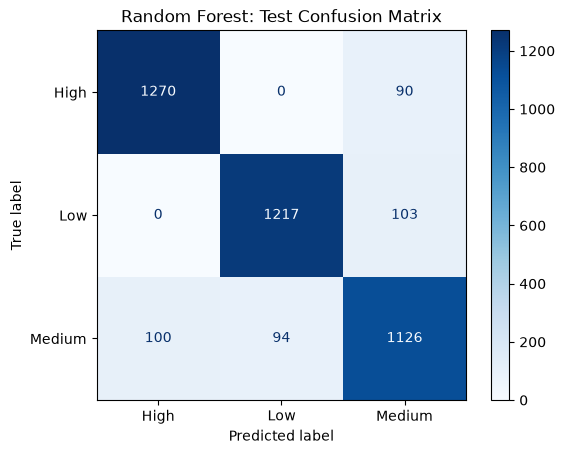

In [45]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=rf_model.classes_,
    display_labels=rf_model.classes_,
    cmap="Blues"
)

plt.title("Random Forest: Test Confusion Matrix")
plt.show()

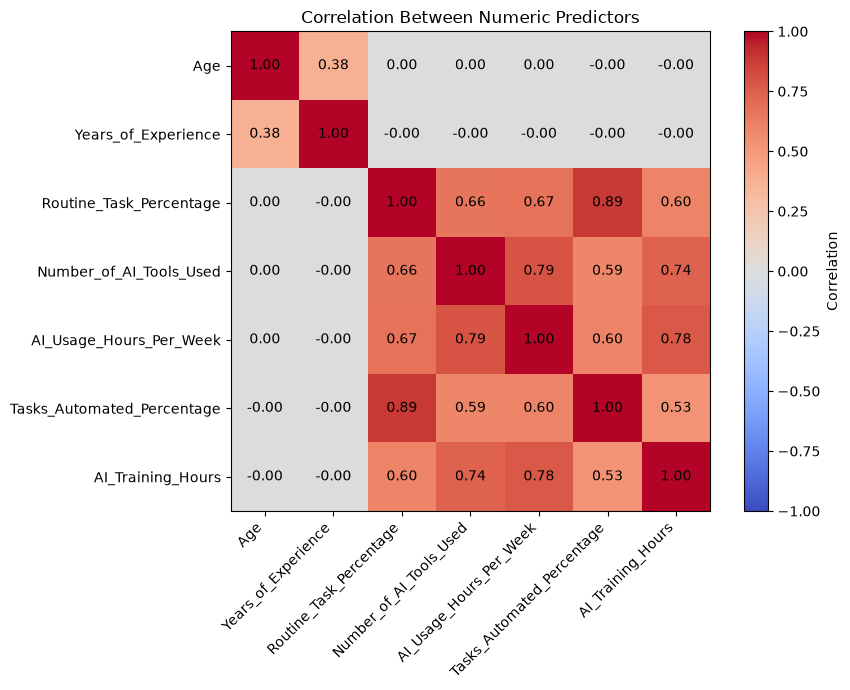

In [49]:
features = [
    "Age",
    "Years_of_Experience",
    "Routine_Task_Percentage",
    "Number_of_AI_Tools_Used",
    "AI_Usage_Hours_Per_Week",
    "Tasks_Automated_Percentage",
    "AI_Training_Hours"
]

correlations = df[features].corr()

fig, ax = plt.subplots(figsize=(9, 7))
heatmap = ax.imshow(correlations, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(features)))
ax.set_xticklabels(features, rotation=45, ha="right")
ax.set_yticks(range(len(features)))
ax.set_yticklabels(features)

for row in range(len(features)):
    for col in range(len(features)):
        ax.text(col, row, f"{correlations.iloc[row, col]:.2f}",
                ha="center", va="center")

ax.set_title("Correlation Between Numeric Predictors")
fig.colorbar(heatmap, ax=ax, label="Correlation")
plt.tight_layout()
plt.show()

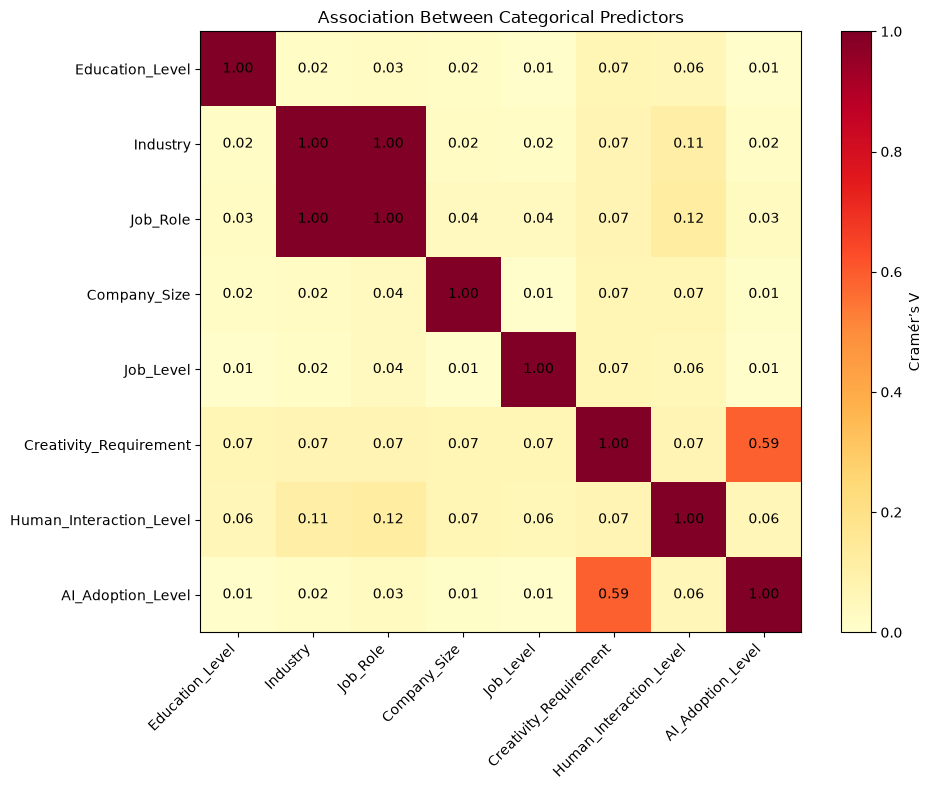

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

categorical_features = [
    "Education_Level",
    "Industry",
    "Job_Role",
    "Company_Size",
    "Job_Level",
    "Creativity_Requirement",
    "Human_Interaction_Level",
    "AI_Adoption_Level"
]

def cramers_v(x, y):
    table = pd.crosstab(x, y)

    if min(table.shape) < 2:
        return np.nan

    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()

    return np.sqrt(
        chi2 / (n * min(table.shape[0] - 1, table.shape[1] - 1))
    )

# Calculate association between every pair of predictors
association = pd.DataFrame(
    index=categorical_features,
    columns=categorical_features,
    dtype=float
)

for row_feature in categorical_features:
    for col_feature in categorical_features:
        association.loc[row_feature, col_feature] = cramers_v(
            df[row_feature],
            df[col_feature]
        )

# Plot the heatmap
fig, ax = plt.subplots(figsize=(10, 8))
heatmap = ax.imshow(association.values, cmap="YlOrRd", vmin=0, vmax=1)

ax.set_xticks(range(len(categorical_features)))
ax.set_xticklabels(categorical_features, rotation=45, ha="right")
ax.set_yticks(range(len(categorical_features)))
ax.set_yticklabels(categorical_features)

for row in range(len(categorical_features)):
    for col in range(len(categorical_features)):
        ax.text(col, row, f"{association.iloc[row, col]:.2f}",
                ha="center", va="center")

ax.set_title("Association Between Categorical Predictors")
fig.colorbar(heatmap, ax=ax, label="Cramér’s V")
plt.tight_layout()
plt.show()

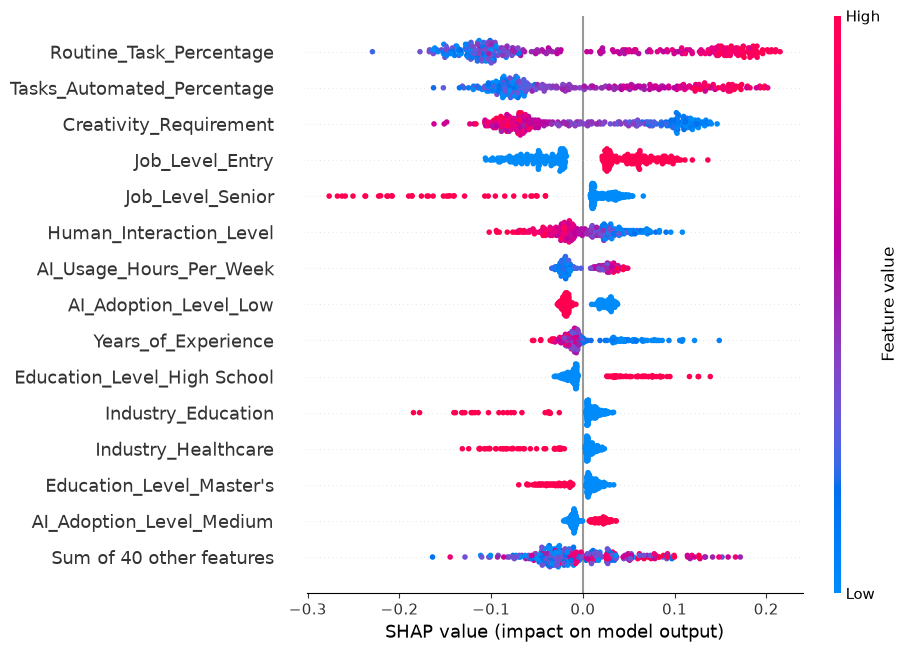

In [52]:
# Use a sample of test profiles
X_sample = X_test.sample(n=min(300, len(X_test)), random_state=42)

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer(X_sample)

# Select the High-risk output
class_index = list(rf_model.classes_).index("High")

shap.plots.beeswarm(
    shap_values[:, :, class_index],
    max_display=15
)